# Phase 11.4 - Meta-policy HGB (Walk-forward + Multi-seed)

Este notebook ejecuta `run_phase11_4_meta_policy_walkforward.py` y muestra estabilidad walk-forward, selección de seed y desempeño final en holdout.

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
PHASE11 = ROOT / 'phases/phase11_offline_rl'
SCRIPT = PHASE11 / 'run_phase11_4_meta_policy_walkforward.py'
OUT = PHASE11 / 'output_phase11_4_meta_policy_walkforward_GBPUSD'

res = subprocess.run(['python', str(SCRIPT)], capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Error running phase11.4 script')

Saved summary: ./phases/phase11_offline_rl/output_phase11_4_meta_policy_walkforward_GBPUSD/GBPUSD_phase11_4_summary.json
Selected seed: 7
Holdout metrics selected seed: {'behavior': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313956810976485, 'cum_net_return': 0.5866498869227144, 'std_net_return': 0.004038152876353244, 'trade_rate': 0.3604004383087158, 'sharpe_ann': 3.14182826856007, 'win_rate_trades': 0.5478395061728395}, 'cql': {'acc_action_3': 0.25528364849833146, 'f1_macro_action_3': 0.24013865365341813, 'avg_net_return': 0.00010810211957526335, 'cum_net_return': 0.388735221992647, 'std_net_return': 0.0030520281593698836, 'trade_rate': 0.2177419364452362, 'sharpe_ann': 2.754555734494888, 'win_rate_trades': 0.5555555555555556}, 'hybrid_advantage': {'acc_action_3': 0.34399332591768633, 'f1_macro_action_3': 0.34245903548058837, 'avg_net_return': 0.00015864660640717464, 'cum_net_return': 0.5704931966402, 'std_net_return': 0.0

In [2]:
import json
import pandas as pd

summary = json.loads((OUT / 'GBPUSD_phase11_4_summary.json').read_text())
cmp = pd.read_csv(OUT / 'GBPUSD_phase11_4_policy_comparison.csv')

print('Selected seed:', summary['selected_seed'])
print('Selected thresholds:', summary['selected_thresholds'])
cmp

Selected seed: 7
Selected thresholds: {'gate_thr': 0.4, 'inf_min': 0.25, 'q_conf_min': 0.25}


,split,policy,avg_net_return,cum_net_return,sharpe_ann,trade_rate,acc_action_3,f1_macro_action_3,std_net_return,win_rate_trades
0,walkforward_test_mean,behavior,0.000154,0.123486,3.292275,0.219167,NaN,NaN,NaN,NaN
1,walkforward_test_mean,cql,0.000190,0.152185,4.839272,NaN,NaN,NaN,NaN,NaN
2,walkforward_test_mean,hybrid_advantage,0.000173,0.138409,3.568394,0.223333,NaN,NaN,NaN,NaN
3,walkforward_test_mean,meta_gate_hgb,0.000154,0.123486,3.292275,0.219167,NaN,NaN,NaN,NaN
4,holdout_selected_seed,behavior,0.000163,0.586650,3.141828,0.360400,0.326196,0.324551,0.004038,0.547840
5,holdout_selected_seed,cql,0.000108,0.388735,2.754556,0.217742,0.255284,0.240139,0.003052,0.555556
6,holdout_selected_seed,hybrid_advantage,0.000159,0.570493,2.961714,0.406285,0.343993,0.342459,0.004166,0.539357
7,holdout_selected_seed,meta_gate_hgb,0.000160,0.575119,3.064963,0.370133,0.330089,0.328574,0.004058,0.544703


In [3]:
wf_seed = pd.read_csv(OUT / 'GBPUSD_phase11_4_walkforward_seed_summary.csv')
wf_seed

,seed,n_folds,cum_behavior_mean,cum_behavior_std,cum_hybrid_mean,cum_hybrid_std,cum_meta_mean,cum_meta_std,avg_meta_mean,sharpe_meta_mean,uplift_meta_vs_behavior_mean,uplift_meta_vs_hybrid_mean,score_meta_mean
0,7,6,0.123486,0.149215,0.138409,0.172123,0.123486,0.149215,0.000154,3.292275,0.0,-0.014923,1.872805
1,11,6,0.123486,0.149215,0.138409,0.172123,0.123486,0.149215,0.000154,3.292275,0.0,-0.014923,1.872805
2,19,6,0.123486,0.149215,0.138409,0.172123,0.123486,0.149215,0.000154,3.292275,0.0,-0.014923,1.872805
3,42,6,0.123486,0.149215,0.138409,0.172123,0.123486,0.149215,0.000154,3.292275,0.0,-0.014923,1.872805
4,77,6,0.123486,0.149215,0.138409,0.172123,0.123486,0.149215,0.000154,3.292275,0.0,-0.014923,1.872805


In [4]:
hold_seed = pd.read_csv(OUT / 'GBPUSD_phase11_4_holdout_by_seed.csv')
hold_seed

,seed,gate_kind,gate_thr,inf_min,q_conf_min,cal_score,meta_acc_action_3,meta_f1_macro_action_3,meta_avg_net_return,meta_cum_net_return,meta_std_net_return,meta_trade_rate,meta_sharpe_ann,meta_win_rate_trades
0,7,hgb,0.4,0.25,0.25,2.713966,0.330089,0.328574,0.00016,0.575119,0.004058,0.370133,3.064963,0.544703
1,11,hgb,0.4,0.25,0.25,2.713966,0.330089,0.328574,0.00016,0.575119,0.004058,0.370133,3.064963,0.544703
2,19,hgb,0.4,0.25,0.25,2.713966,0.330089,0.328574,0.00016,0.575119,0.004058,0.370133,3.064963,0.544703
3,42,hgb,0.4,0.25,0.25,2.713966,0.330089,0.328574,0.00016,0.575119,0.004058,0.370133,3.064963,0.544703
4,77,hgb,0.4,0.25,0.25,2.713966,0.330089,0.328574,0.00016,0.575119,0.004058,0.370133,3.064963,0.544703


In [5]:
wf_rows = pd.read_csv(OUT / 'GBPUSD_phase11_4_walkforward_rows.csv')
wf_rows.head()

,seed,fold_id,train_n,cal_n,test_n,train_end_ts,cal_end_ts,test_start_ts,test_end_ts,gate_kind,...,avg_cql,avg_hybrid,avg_meta,sharpe_behavior,sharpe_cql,sharpe_hybrid,sharpe_meta,trade_behavior,trade_hybrid,trade_meta
0,7,1,2560,640,800,2010-07-30 16:00:00,2011-01-07 14:00:00,2011-01-07 15:00:00,2011-10-31 02:00:00,constant,...,0.000056,0.000045,0.000045,2.249224,2.809558,2.249224,2.249224,0.07375,0.07375,0.07375
1,7,2,3200,800,800,2011-01-07 14:00:00,2011-10-31 02:00:00,2011-10-31 03:00:00,2013-05-28 10:00:00,constant,...,0.000142,0.000113,0.000113,3.495380,6.903754,3.495380,3.495380,0.23000,0.23000,0.23000
2,7,3,3840,960,800,2011-09-27 10:00:00,2013-05-28 10:00:00,2013-05-28 11:00:00,2015-03-11 14:00:00,constant,...,0.000046,-0.000050,-0.000050,-1.190839,1.949333,-1.190839,-1.190839,0.31500,0.31500,0.31500
3,7,4,4480,1120,800,2012-12-31 09:00:00,2015-03-11 14:00:00,2015-03-11 15:00:00,2016-02-08 08:00:00,constant,...,0.000075,0.000173,0.000144,5.407153,2.646262,6.398462,5.407153,0.11875,0.12625,0.11875
4,7,5,5120,1280,800,2013-10-09 02:00:00,2016-02-08 08:00:00,2016-02-08 09:00:00,2016-07-22 06:00:00,constant,...,0.000646,0.000627,0.000545,7.306851,8.182792,7.972255,7.306851,0.17000,0.18750,0.17000


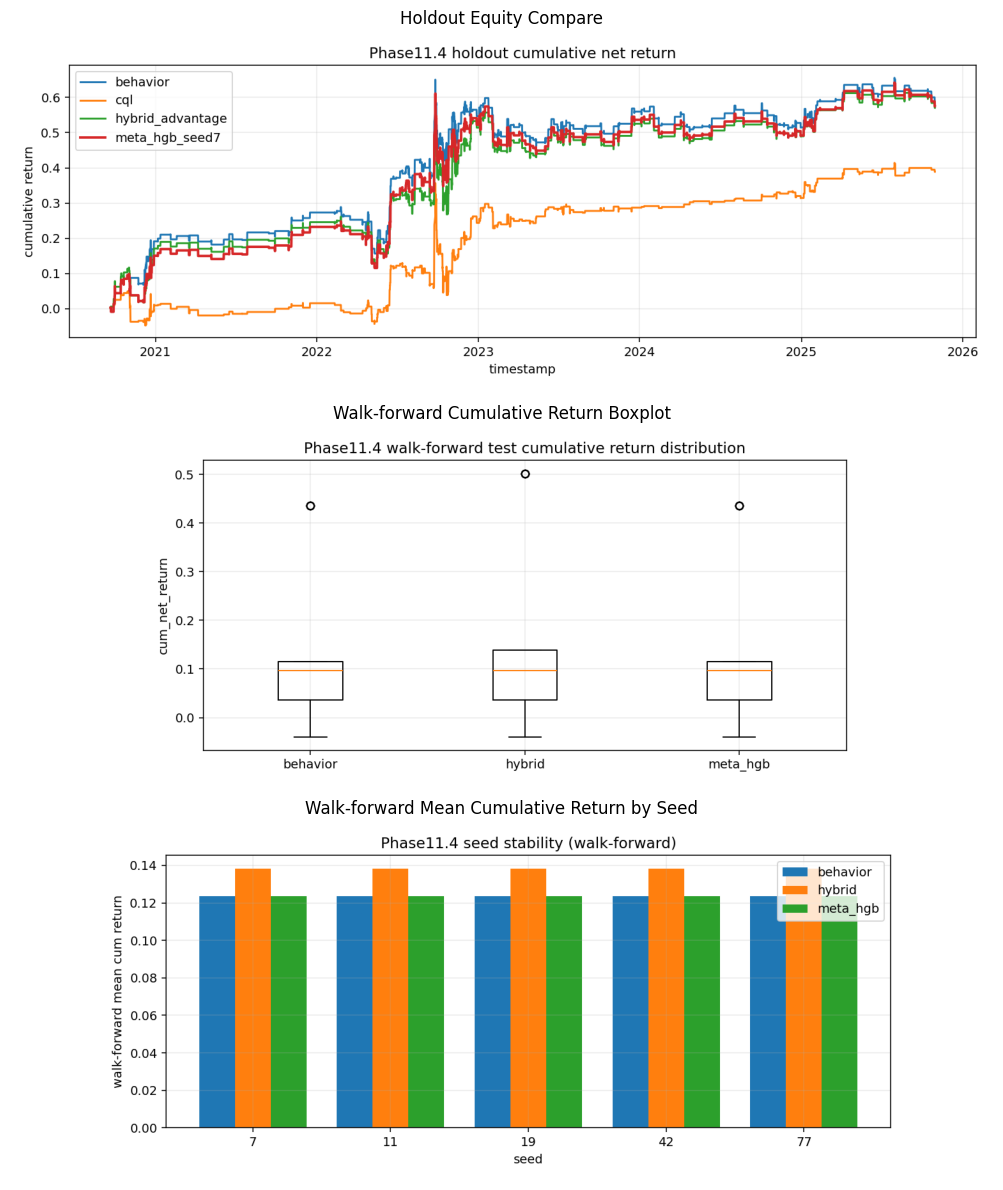

In [6]:
import matplotlib.pyplot as plt

img1 = plt.imread(OUT / 'GBPUSD_phase11_4_holdout_equity_compare.png')
img2 = plt.imread(OUT / 'GBPUSD_phase11_4_walkforward_cum_boxplot.png')
img3 = plt.imread(OUT / 'GBPUSD_phase11_4_walkforward_seed_mean_cum.png')

fig, ax = plt.subplots(3, 1, figsize=(14, 12))
ax[0].imshow(img1); ax[0].axis('off'); ax[0].set_title('Holdout Equity Compare')
ax[1].imshow(img2); ax[1].axis('off'); ax[1].set_title('Walk-forward Cumulative Return Boxplot')
ax[2].imshow(img3); ax[2].axis('off'); ax[2].set_title('Walk-forward Mean Cumulative Return by Seed')
plt.tight_layout()
plt.show()